## First let's load needed packages

In [15]:
import pyrecon
import pandas as pd


from pyrecon.stepwise import find_best_set_of_chrons
from pyrecon.plotting import plot_full_reconstruction

##  Let's upload chronologies as a dataframe

In [16]:
# ── Loading all the chronologies ─────────────────

excel_path = '../Data/upper-colorado-trees.xls'
sheet_name = 'residual chrons'  
header_row = 1                   


year_min, year_max = 1490, 1995      # full reconstruction period
calib_start, calib_end = 1906, 1995  # instrumental calibration period


#columns = [
    #'YEAR',
    #'PIC', 'WIL', 'COL', 'PLU', 'MCP', 'SAR', 'UNA', 'ATR', 'PUM', 'RED',
    #'RIF', 'CAT', 'GMR', 'ENC', 'DOU', 'TRG', 'COD', 'MTR', 'PRP', 'NPU',
   # 'SLK', 'EAG', 'BEN', 'RUS', 'JFU', 'FBN', 'DJM', 'NUR', 'RPC', 'WED',
#]


columns = [
    'YEAR',
    'ATR', 'BEN', 'CAT', 'COD', 'COL', 'DIL', 'DJM', 'DOU', 'EAG', 'ENC',
    'FBN', 'GMR', 'GOU', 'LAN', 'MCP', 'MTR', 'NPU', 'NUR', 'PIC', 'PLU',
    'PUM', 'RED', 'RIF', 'RUS', 'RPC', 'SAR', 'SLK', 'TRG', 'WED','UNA','WIL',
]



# ── Selecting only needed chronologies ────────────────

df = pd.read_excel(excel_path, sheet_name=sheet_name, header=header_row)
df_sel = df[columns].copy()


# ── Selecting only needed year range ────────────────

mask = (df_sel['YEAR'] >= year_min) & (df_sel['YEAR'] <= year_max)
df_years = df_sel.loc[mask].copy()
df_years = df_years.set_index('YEAR')


## Let's upload observed/measured values as a dataframe

In [17]:
# ── Load measured streamflow ──────────────

nf = pd.read_excel('../Data/guage data.xlsx', header=2, index_col=0)
nf = nf.iloc[:, [0]]               
nf = nf.loc[calib_start:calib_end] 


# ── Prepare X and Y ────────────

X = df_years.loc[year_min:year_max]

# ── Prepare X and Y for the calibration ────────────

data = X.join(nf, how='inner').dropna()
X_calib = data[df_years.columns]  # shape: (92, 30)
y_calib = data[nf.columns[0]]   # shape: (92,)

print(f"Calibration period : {X_calib.index[0]}–{X_calib.index[-1]}  ({len(X_calib)} years)")
print(f"Full recon period  : {X.index[0]}–{X.index[-1]}  ({len(X)} years)")

Calibration period : 1906–1995  (90 years)
Full recon period  : 1490–1995  (506 years)


# Package examples


=== Best subset (sequential selection) ===
Direction: forward
Number of chrons : 8
Best chrons: ['DJM', 'DOU', 'PUM', 'RED', 'RIF', 'SAR', 'TRG', 'WIL']
CV neg-MSE: -6729104.0333 ± 1884005.2328


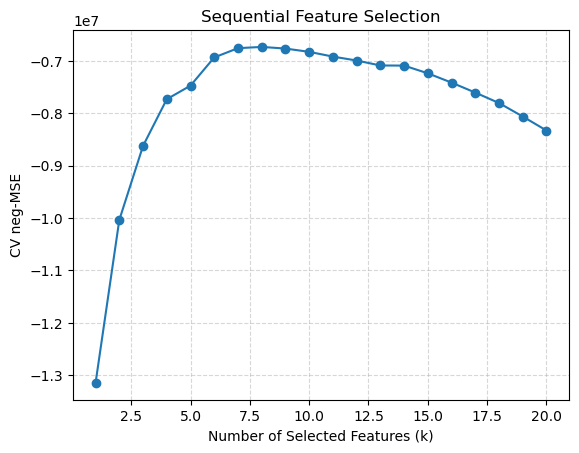

In [18]:
number_of_chrons, best_chrons, best_score, best_std, results = find_best_set_of_chrons(
    X_calib, y_calib, 20, direction="forward", plot=True)